# 文本 02｜顺序、记忆和结果：用图比较四种模型

本页把同一批评论交给 RNN、LSTM、GRU 和平均 Embedding。先看整段学习曲线，再观察同一句话的逐字状态，最后用验证错例提出下一步问题。

平均 Embedding 是有意保留的简单基线：它平均有效字符向量，不使用循环状态；同一组字符仅交换先后时，它的句子表示不变。RNN 类模型会按顺序更新，但“能利用顺序”不等于本次数据上一定获得更高成绩。

**先写预测：**哪种模型可能更快？哪种参数更多？如果简单基线更好，应先检查数据与实验条件，而不是修改结果来符合预期。

> **课堂预览**　本页的图是 2026-10-17 的本地 CPU 运行快照，重新执行会更新；人工图解与训练结果已分别标明。只阅读可直接展开输出，实验时仍需从第一格执行。真实评论原文的打印未嵌入快照；有本地课程数据时运行对应格查看。

In [1]:
%matplotlib inline
from pathlib import Path
import sys
import torch
import matplotlib.pyplot as plt

# 支持从仓库根、03_rnn_lab、当前任务子目录启动，不依赖盘符或安装 rnn_lab。
LAB_DIR = next((candidate for base in (Path.cwd(), *Path.cwd().parents)
                for candidate in (base, base / "03_rnn_lab")
                if (candidate / "rnn_lab").is_dir()), None)
if LAB_DIR is None:
    raise FileNotFoundError("请从课程仓库、03_rnn_lab 或本任务目录启动 Notebook。")
if str(LAB_DIR) not in sys.path:
    sys.path.insert(0, str(LAB_DIR))
DATA_DIR = LAB_DIR / "06_text_classification" / "data"
torch.set_num_threads(1)
from rnn_lab import configure_chinese_font, seed_everything
configure_chinese_font()
from rnn_lab.text_data import (load_text_data, build_vocab, encode_text,
    make_text_dataloaders, text_data_diagnostics, save_text_preprocessing,
    load_text_preprocessing)
from rnn_lab.text_engine import (TextExperimentConfig, run_text_experiment,
    predict_text, evaluate_text_final, export_text_experiments_csv, save_text_run)
from rnn_lab.text_plots import (plot_text_history, plot_text_confusion,
    plot_text_comparison, plot_text_states, text_examples)
print("实验室：", LAB_DIR, "；CPU 线程：", torch.get_num_threads())

实验室： <实验室目录> ；CPU 线程： 1


In [2]:
from dataclasses import replace
from datetime import datetime
import uuid
from rnn_lab.text_observation import observe_text_recurrence

data = load_text_data(DATA_DIR)
vocab = build_vocab(record["text"] for record in data.splits["train"])
base = TextExperimentConfig(
    name="对比", cell_type="rnn", embedding_dim=32, hidden_size=32,
    num_layers=1, dropout=0.0, readout="last", max_length=100,
    epochs=6, batch_size=64, learning_rate=0.003, seed=42, device="cpu",
)
RUN_DIR = (LAB_DIR / "outputs" / "text" / "02_comparison" /
           (datetime.now().strftime("%Y%m%d_%H%M%S") + "_" + uuid.uuid4().hex[:8]))
RUN_DIR.mkdir(parents=True, exist_ok=False)
print("本轮输出：", RUN_DIR)
print("实验前预测（请先写在Markdown）：顺序模型会在哪类评论上更有帮助？")

本轮输出： <实验室目录>\outputs\text\02_comparison\20261017_135233_d4bf9319
实验前预测（请先写在Markdown）：顺序模型会在哪类评论上更有帮助？


## 比较之前，先区分模型传递的状态

下面是结构提示，不是完整的门公式。RNN 和 GRU 各传递 h；LSTM 传递 h 与 c，两者不能互换。门控改变信息更新的方式，是否有帮助仍要由本次实验判断。

四组共用数据划分、词表、最大长度、训练预算。H 相同并不意味着参数量相同；后面的图会同时保留参数量和耗时。

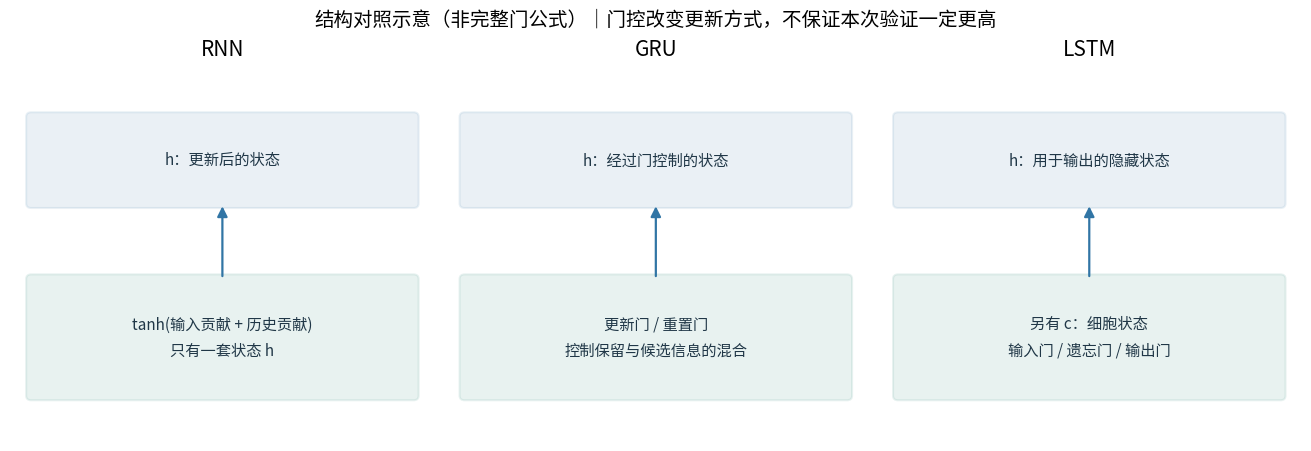

In [3]:
from rnn_lab.teaching_visuals import plot_cell_memory_map
import matplotlib.pyplot as plt

fig = plot_cell_memory_map()
plt.show()
plt.close(fig)

## 一次运行四组，保留所有记录

每组从相同 seed 重新初始化，不能接着上一模型训练。不同结构需要不同数量的随机数，因此不能声称模型初始权重完全相同。保持统一训练预算，结果只对应当前数据、种子和配置。单层循环 dropout 不生效；本例明确为0。

RNN 有效last 验证Loss= 0.7037 验证Accuracy= 0.648 参数量= 100770 训练秒数= 1.144


LSTM 有效last 验证Loss= 0.4271 验证Accuracy= 0.822 参数量= 107106 训练秒数= 1.177


GRU 有效last 验证Loss= 0.4218 验证Accuracy= 0.806 参数量= 104994 训练秒数= 2.967


平均Embedding 验证Loss= 0.3859 验证Accuracy= 0.85 参数量= 98658 训练秒数= 0.299


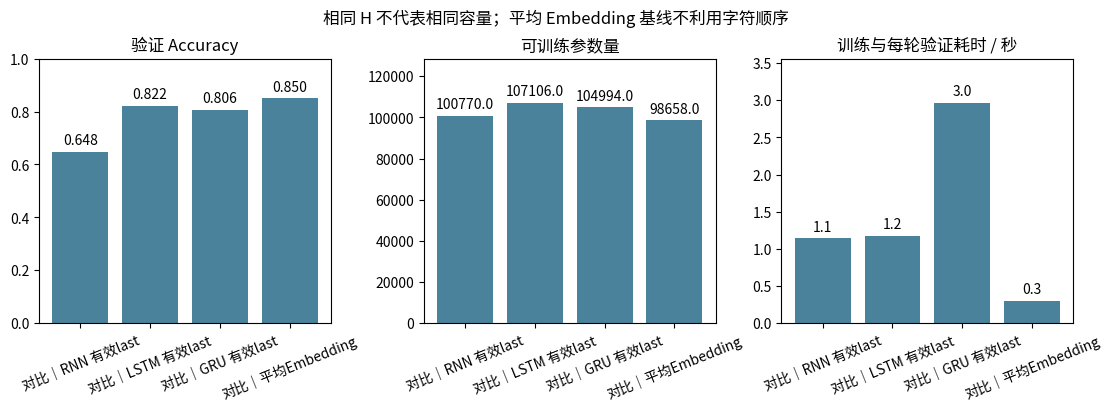

WindowsPath('D:/Code_for_all/2026DeeplearningDemo/03_rnn_lab/outputs/text/02_comparison/20261017_135233_d4bf9319/all_experiments.csv')

In [4]:
results = []
for cell_type in ("rnn", "lstm", "gru", "mean_embedding"):
    label = "平均Embedding" if cell_type == "mean_embedding" else cell_type.upper() + " 有效last"
    config = replace(base, name="对比｜" + label, cell_type=cell_type)
    result = run_text_experiment(config, data, vocab=vocab, evaluate_test=False)
    results.append(result)
    print(label, "验证Loss=", round(result["val_metrics"]["loss"], 4),
          "验证Accuracy=", round(result["val_metrics"]["accuracy"], 4),
          "参数量=", result["parameter_count"], "训练秒数=", round(result["elapsed_seconds"], 3))
    save_text_run(result, RUN_DIR)
fig = plot_text_comparison(results)
fig.savefig(RUN_DIR / "model_comparison.png", dpi=140, bbox_inches="tight")
plt.show()
export_text_experiments_csv(results, RUN_DIR / "all_experiments.csv")

## 不只看终点：四条学习轨迹有没有讲出不同的故事？

左图比较每轮验证 Loss，右图比较验证 Accuracy。颜色对应模型，横轴对应已完成的训练轮数。两条线可能交叉，所以“第 1 轮领先”与“当前预算结束领先”不一定相同。

用一句带条件的话描述结果：“在当前数据、种子和轮数下，……”。再对照上图参数量和耗时，判断提高是否伴随成本。一次种子的轨迹不能证明普遍排名。

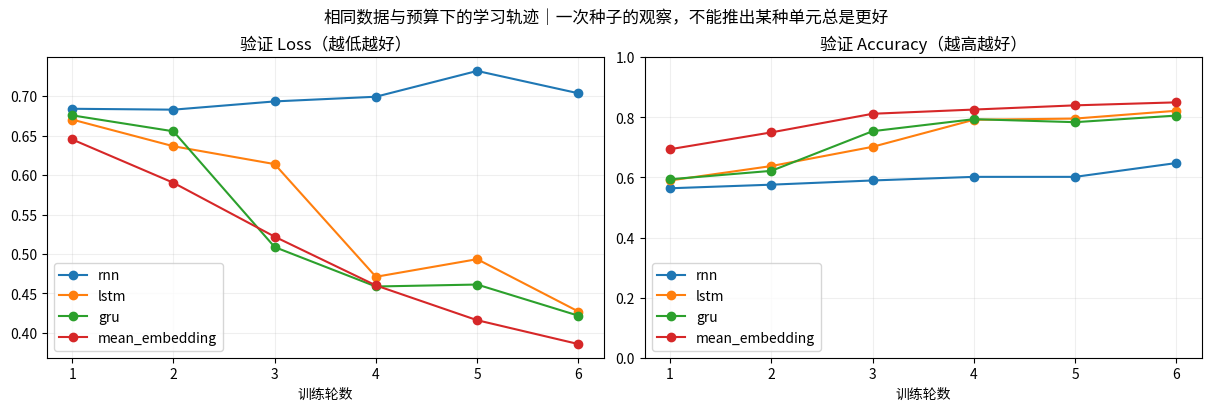

In [5]:
from rnn_lab.teaching_visuals import plot_learning_comparison
import matplotlib.pyplot as plt

fig = plot_learning_comparison(results)
fig.savefig(RUN_DIR / "learning_curves_comparison.png", dpi=140, bbox_inches="tight")
plt.show()
plt.close(fig)

## 沿着同一句话看状态：每一列是一个已读位置

下面让三种已训练模型都读同一句教师人工探针。它不属于正式数据评分；图中数值来自当前模型的实际前向传播，并与逐步重放核对。

热力图横轴是字符位置，纵轴是隐藏单元。红正蓝负表示状态数值，不是情感标签；LSTM 另画 c，h/c 和不同模型共用色阶。观察“但是”前后哪些单元改变了，再提醒自己：**颜色变化不能证明该单元理解了转折，跨模型同编号单元也没有语义一一对应。**

同一教师人工探针（不计入验证成绩）： 房间很干净，但是隔音太差了。
rnn 有效字符： 房间很干净,但是隔音太差了。 逐步核对最大误差： 2.5331974029541016e-07


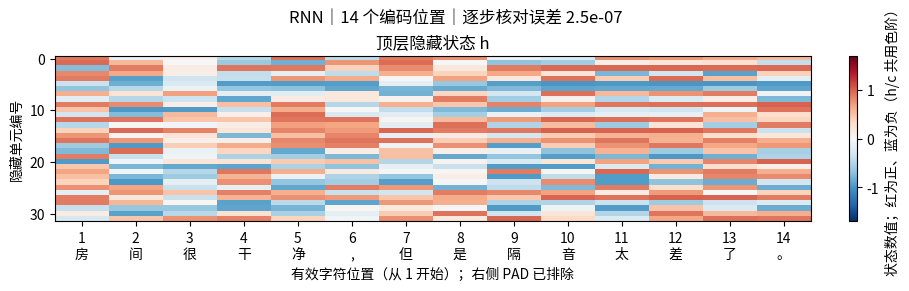

lstm 有效字符： 房间很干净,但是隔音太差了。 逐步核对最大误差： 1.1920928955078125e-07


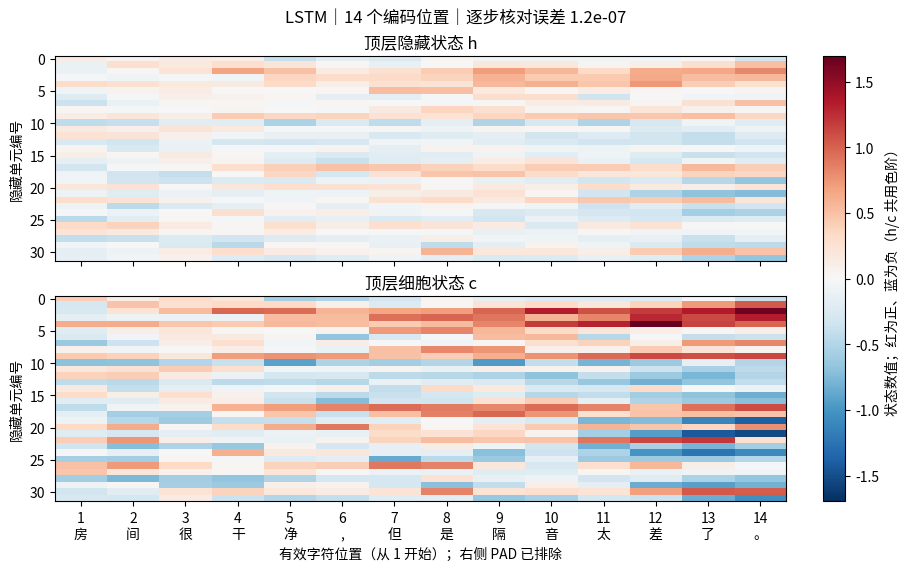

gru 有效字符： 房间很干净,但是隔音太差了。 逐步核对最大误差： 2.384185791015625e-07


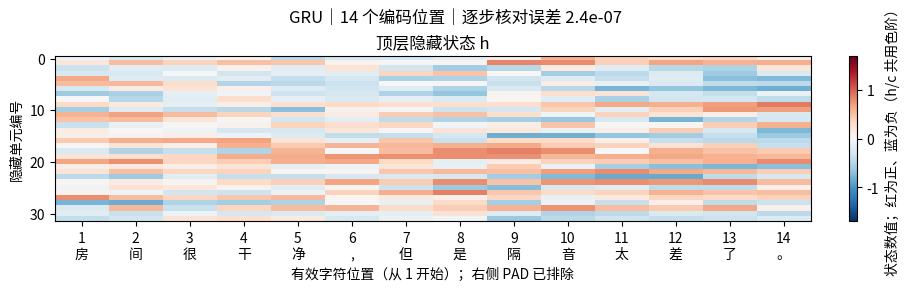

In [6]:
OBSERVE_REVIEW = "房间很干净，但是隔音太差了。"  # 教师人工探针；状态来自真实训练模型
print("同一教师人工探针（不计入验证成绩）：", OBSERVE_REVIEW)
traces = [observe_text_recurrence(result, OBSERVE_REVIEW) for result in results[:3]]
limits = [abs(trace["hidden_states"]).max().item() for trace in traces]
limits += [abs(trace["cell_states"]).max().item() for trace in traces
           if trace["cell_states"] is not None]
shared_limit = max(max(limits), 1e-6)
for result, trace in zip(results[:3], traces):
    print(result["config"].cell_type, "有效字符：", "".join(trace["characters"]),
          "逐步核对最大误差：", trace["replay_max_error"])
    fig = plot_text_states(trace, color_limit=shared_limit)
    fig.savefig(RUN_DIR / (result["config"].cell_type + "_states.png"),
                dpi=140, bbox_inches="tight")
    plt.show()

## 假如读到这里就停下来，模型会怎样判断？

上方折线把同一人工句子拆成逐渐变长的前缀，每次走完整推断流程。下方柱子显示相邻隐藏状态的变化幅度。可以逐字指着图讲“目前已经读到了什么”，观察转折后预测是否变化。

残缺前缀未必有明确情感，训练时也没有给每个前缀提供标签。因此这不是逐字准确率。状态跳变大小也不是注意力、词的重要性或错误原因。把句子换成“服务一般，但是房间非常干净”，再用同一模型观察即可。

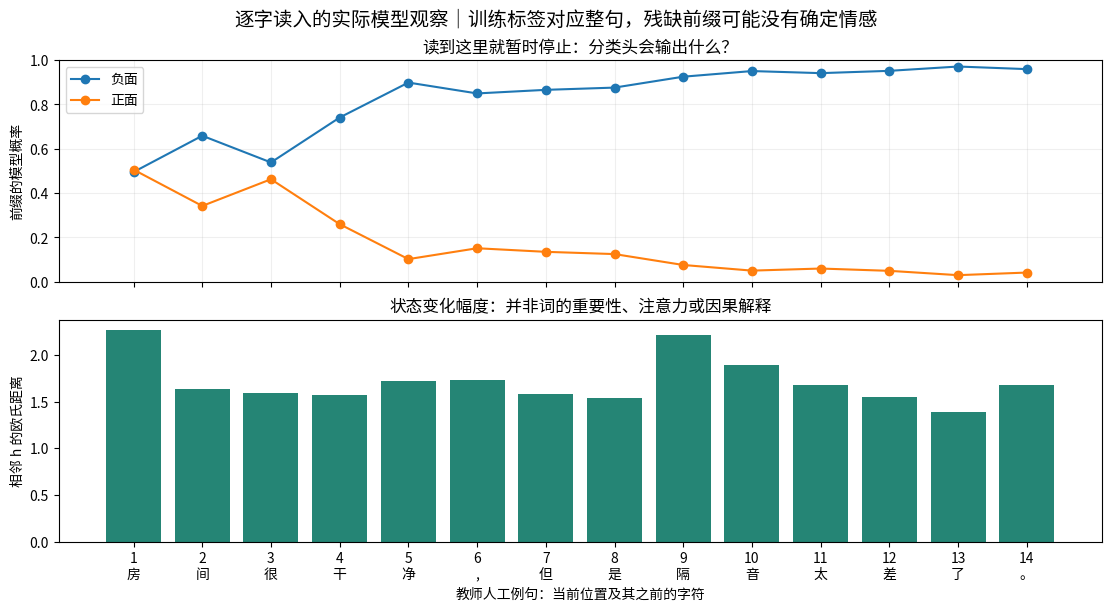

In [7]:
from rnn_lab.teaching_visuals import plot_prefix_predictions
import matplotlib.pyplot as plt

probe_result = next(item for item in results if item["config"].cell_type == "gru")
fig = plot_prefix_predictions(probe_result, OBSERVE_REVIEW)
fig.savefig(RUN_DIR / "prefix_predictions.png", dpi=140, bbox_inches="tight")
plt.show()
plt.close(fig)

## 验证错例：长度、未知字、否定与转折

先逐条读评论和原标签，再讨论可能原因。未知字比例和截断只是描述证据，不能直接解释每个错误。若当前模型没有某类错误，如实记录，不挑测试集凑错例。打乱句子可能破坏语义，不能把原标签无条件当作打乱文本的新标注。

In [8]:
for result in results:
    print("\n模型：", result["config"].name)
    for example in text_examples(result, correct=False, limit=3):
        print(example)
print("编码诊断：", text_data_diagnostics(data, vocab, base.max_length))

## 把错例变成可检查的问题

这里固定观察 GRU，避免只展示表现最好的模型。左图分别按截断和 UNK 分组，标出“错误数/本组样本数”，同一条评论可以同时属于两个维度。小组只有几条时，百分比容易波动。右图比较正确与错误样本的原始长度分布。

先提出一个可验证的问题，例如“后半段被截断的评论是否更容易错？”这张图只提示关联，不能证明原因。下一步才是控制其他条件、只改最大长度，并使用验证集比较。不要为了寻找解释反复查看测试成绩。

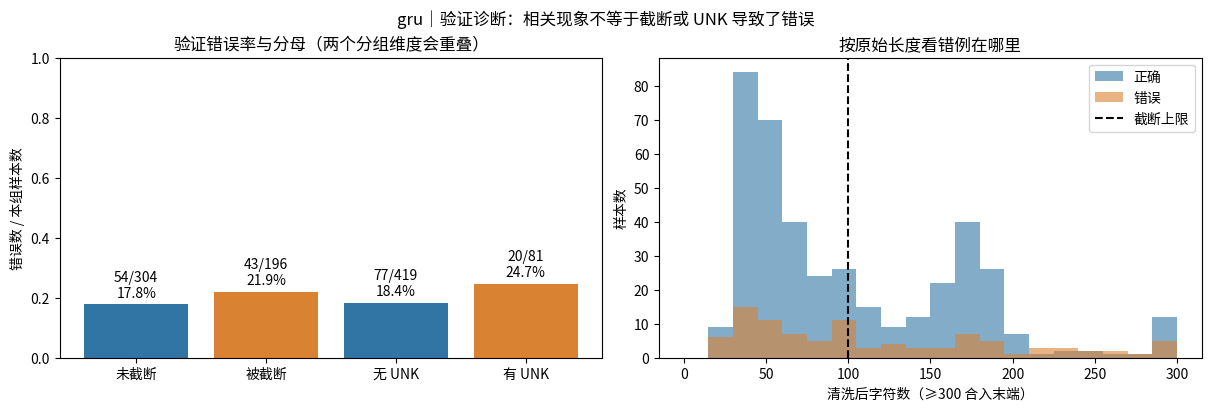

In [9]:
from rnn_lab.teaching_visuals import plot_validation_groups
import matplotlib.pyplot as plt

fig = plot_validation_groups(probe_result)
fig.savefig(RUN_DIR / "validation_groups.png", dpi=140, bbox_inches="tight")
plt.show()
plt.close(fig)

## 固定方案后才显式评价测试集

先写验证选型理由，再开启 `RUN_FINAL_TEST`，只运行本单元。默认按验证 Accuracy、再按验证 Loss 选择；可改为事先写明的参数量约束。不要根据 test 继续挑模型、seed 或最大长度。测试缓存只属于第一次评价的模型状态；模型发生变化必须拒绝旧缓存。

In [10]:
RUN_FINAL_TEST = False
selected = max(results, key=lambda result: (result["val_metrics"]["accuracy"],
                                           -result["val_metrics"]["loss"]))
print("当前依据验证集选定：", selected["config"].name)
if RUN_FINAL_TEST:
    metrics = evaluate_text_final(selected)
    print("固定方案最终测试：", {key: metrics[key] for key in ("loss", "accuracy")})
else:
    print("最终测试关闭，CSV 中 test 项留空。")
export_text_experiments_csv(results, RUN_DIR / "all_experiments.csv")
print("保留了", len(results), "组记录；目录：", RUN_DIR)

当前依据验证集选定： 对比｜平均Embedding
最终测试关闭，CSV 中 test 项留空。
保留了 4 组记录；目录： <实验室目录>\outputs\text\02_comparison\20261017_135233_d4bf9319


**结论记录：**哪组验证结果较好，付出了多少参数和时间？平均 Embedding 是否已经有用？引用一个否定或转折例子，区分观察与推测。选定方案的局限是什么？课后进入 [03](03_自主修改与挑战.ipynb) 自己完成关键代码，而不是原样复制训练入口。

## 保存与结束

本页输出写入带运行标识的新目录，保留旧记录。先保存 Notebook，再按需运行下一格关闭图片。本页不自动关闭内核；不要为了重新看图反复训练。共享服务器每次只运行一个训练任务。

In [11]:
# 需要重新实验时建议重启内核，从头运行；本格仅关闭图片。
plt.close("all")